# Minicurso: poda, quantização e implantação de CNNs

**SignEdge** reconhece as 61 configurações de mão (CM) da LIBRAS em tempo real e 100% offline num celular. Neste laboratório, você pega o aluno já destilado (MobileNetV4 + ramo dos 21 pontos) e faz o mesmo caminho do arquivo que roda no app:

1. **Inspecionar** o modelo e medir a acurácia de referência (FP32).
2. **Podar** 50% das conexões: L1 uniforme contra LAMP, e o que isso muda (ou não) em tamanho e latência.
3. **Calibrar** a confiança com uma temperatura T ajustada **depois da poda**.
4. **Decidir** nas 61 classes: cobertura e acerto por limiar, e o top-3 que o app mostra.
5. **Quantizar** em Int8 (PTQ) com o ramo dos pontos em float32 e medir acurácia, tamanho e latência.
6. **Implantar** o `.tflite` podado no app Flutter e conferir a predição no celular.

**Dados do kit.** O aluno é o do fold 0 do LOSO (treinado nos atores C2–C5). Ele é avaliado no ator **C1**, que nunca viu: 226 pausas, 2 frames cada, já recortados na vista 224 (a mesma `EvalView` do treino e do app). O kit traz ainda as predições fora do fold dos 5 folds, do aluno denso e do podado com LAMP, para ajustar T sem olhar o C1. O ator C6 não está aqui: ele é o teste final do projeto e foi medido uma única vez.

**Unidade de avaliação: a pausa** (média dos logits dos frames de um trecho parado da mão), não o frame.

> Colab: *Ambiente de execução → CPU* basta. Tempo total: ~10 min.

In [1]:
# Preparação: no Colab, envie o minicurso.zip (código + kit); localmente, usa o repositório.
import os, sys, zipfile, subprocess
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    if not Path("signedge").exists():
        if not Path("minicurso.zip").exists():
            from google.colab import files
            files.upload()  # escolha o minicurso.zip
        zipfile.ZipFile("minicurso.zip").extractall("signedge")
    os.chdir("signedge")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "litert-torch==0.9.4", "timm==1.0.30", "pyyaml"], check=True)
    RAIZ, KIT = Path.cwd(), Path.cwd() / "kit"
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(RAIZ)
    KIT = RAIZ / "research/experiments/kit/extraido/kit"
    if not KIT.exists():
        with zipfile.ZipFile(RAIZ / "research/experiments/kit/minicurso.zip") as z:
            z.extractall(KIT.parent, members=[n for n in z.namelist() if n.startswith("kit/")])
sys.path.insert(0, str(RAIZ))
SAIDA = RAIZ / "research/experiments/lab"
SAIDA.mkdir(parents=True, exist_ok=True)
print("raiz:", RAIZ, "| kit:", KIT)

raiz: /home/alguem/Documentos/SignEdge | kit: /home/alguem/Documentos/SignEdge/research/experiments/kit/extraido/kit


## 1. O aluno e a acurácia de referência

O aluno tem duas entradas: a imagem RGB da vista 224 e os 21 pontos do MediaPipe em pixels dessa vista. Os pontos passam por uma normalização (centro e raio médio da mão) e por um MLP pequeno; o vetor dele é concatenado às 1280 features da MobileNetV4 antes da cabeça de 61 classes.

In [2]:
import copy, json
import numpy as np
import torch
from research.optimization.quantizer import load_student

torch.set_num_threads(4)
modelo, registro = load_student(KIT / "student")
dados = np.load(KIT / "data.npz")
info = json.loads((KIT / "info.json").read_text())

def contar(m):
    return sum(p.numel() for p in m.parameters())

print(f"aluno {registro['stage']}, fold {registro['fold']}, avaliado em {info['val_actor']}")
print(f"parâmetros: total {contar(modelo)/1e6:.2f} M | MobileNetV4 {contar(modelo.backbone)/1e6:.2f} M | "
      f"ramo dos pontos {contar(modelo.landmarks)/1e3:.1f} k | cabeça {tuple(modelo.head.weight.shape)}")
print(modelo.landmarks)
print(f"kit: {info['frames']} frames, {info['pauses']} pausas; calibração: {info['calib_frames']} frames")

/home/alguem/Documentos/SignEdge/.venv-tflite/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


aluno student_kd, fold 0, avaliado em C1
parâmetros: total 2.60 M | MobileNetV4 2.49 M | ramo dos pontos 22.0 k | cabeça (61, 1408)
LandmarkEncoder(
  (net): Sequential(
    (0): Linear(in_features=42, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
  )
)
kit: 442 frames, 226 pausas; calibração: 160 frames


In [3]:
from research.training.metrics import pause_logits, softmax, expected_calibration_error

RGB, PONTOS = dados["rgb"], dados["landmarks"]
ROTULOS, PAUSAS = dados["labels"], dados["pause_ids"]

def lotes(tam=64):
    # Vistas do kit como o app entrega: RGB NHWC em [0, 1] e pontos em pixels da vista.
    for i in range(0, len(RGB), tam):
        yield RGB[i:i+tam].astype(np.float32) / 255, PONTOS[i:i+tam]

@torch.no_grad()
def logits_pytorch(m):
    m.eval()
    return np.concatenate([m(torch.from_numpy(r).permute(0, 3, 1, 2), torch.from_numpy(p)).numpy()
                           for r, p in lotes()])

def metricas(logits):
    pl, rot = pause_logits(logits, ROTULOS, PAUSAS)
    return {"pausa_61": (pl.argmax(1) == rot).mean(),
            "quadro_61": (logits.argmax(1) == ROTULOS).mean(),
            "ece_pausa": expected_calibration_error(softmax(pl), rot)}

def mostra(nome, m):
    print(f"{nome:28} pausa {m['pausa_61']:6.1%} | quadro {m['quadro_61']:6.1%} | ECE {m['ece_pausa']:.3f}")

ref = logits_pytorch(modelo)
mostra("FP32 (PyTorch)", metricas(ref))

FP32 (PyTorch)               pausa  81.0% | quadro  79.6% | ECE 0.107


**Como ler.** *Pausa*: acerto entre as 61 CMs, por pausa (média dos logits dos frames). *Quadro*: acerto frame a frame. *ECE*: erro de calibração, a distância entre a confiança e a acurácia (0 = perfeito).

O kit usa 2 frames por pausa, então o número aqui não é idêntico ao do fold 0 com todos os frames. No LOSO completo (5 folds, 1.160 pausas) o aluno faz **75,8 ± 4,8%** nas 61 classes; o C1 é um dos atores mais fáceis.

## 2. Poda: zerar metade das conexões

Podamos só as camadas que aguentam: as convoluções 1×1 (pointwise) e as lineares do ramo dos pontos, que somam ~92% dos parâmetros. As depthwise, as convs 3×3, as normas e a cabeça ficam inteiras.

Dois critérios, ambos sem nenhum treino depois:

- **L1 uniforme**: em *cada* camada, zera a mesma fração dos pesos de menor módulo.
- **LAMP** (Lee et al., ICLR 2021): o score de um peso é $w_u^2 / \sum_{v \ge u} w_v^2$ (pesos da camada em ordem crescente). A escala de cada camada some, e um **limiar global** decide quanto podar em cada uma.

In [4]:
from research.optimization.pruner import attach_masks, bake, compute_masks, prunable, set_masks, sparsity_report

def podado(criterio, fracao):
    m = copy.deepcopy(modelo)
    attach_masks(m)
    set_masks(m, compute_masks([x for _, x in prunable(m)], fracao, criterio))
    return bake(m)

resultados = {}
for criterio in ("l1_uniform", "lamp"):
    for fracao in (0.3, 0.5, 0.7):
        m = podado(criterio, fracao)
        resultados[(criterio, fracao)] = (m, metricas(logits_pytorch(m)))
        mostra(f"{criterio} {fracao:.0%}", resultados[(criterio, fracao)][1])

l1_uniform 30%               pausa  78.3% | quadro  77.1% | ECE 0.221


l1_uniform 50%               pausa  55.8% | quadro  55.2% | ECE 0.315


l1_uniform 70%               pausa   1.8% | quadro   2.0% | ECE 0.387


lamp 30%                     pausa  81.0% | quadro  79.9% | ECE 0.169


lamp 50%                     pausa  81.0% | quadro  79.0% | ECE 0.436


lamp 70%                     pausa  17.7% | quadro  18.3% | ECE 0.069


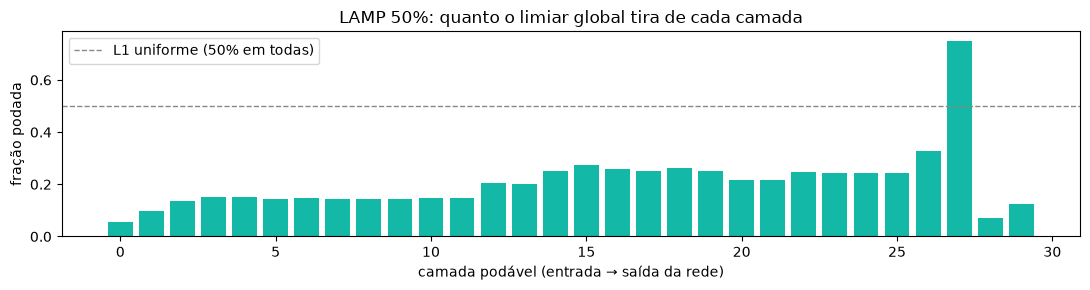

In [5]:
import matplotlib.pyplot as plt

camadas = sparsity_report(resultados[("lamp", 0.5)][0])["per_layer"]
plt.figure(figsize=(11, 3))
plt.bar(range(len(camadas)), list(camadas.values()), color="#14b8a6")
plt.axhline(0.5, color="#888", ls="--", lw=1, label="L1 uniforme (50% em todas)")
plt.ylabel("fração podada"); plt.xlabel("camada podável (entrada → saída da rede)")
plt.title("LAMP 50%: quanto o limiar global tira de cada camada"); plt.legend(); plt.tight_layout(); plt.show()

**O que aconteceu.** A 50%, o L1 uniforme desaba e o LAMP praticamente não perde acurácia: as camadas não têm a mesma redundância, e o LAMP poda de ~5% a ~75% conforme a camada. A camada mais podada é a projeção `conv_head` (960 → 1280), que sozinha tem metade dos pesos podáveis. A 70%, até o LAMP colapsa.

**Mas olhe o ECE.** O LAMP 50% acerta o mesmo e a calibração quebra: a poda encolhe a escala dos logits. Quem usa a confiança (o app usa) precisa **reajustar T depois de podar**, que é a próxima seção.

**E o fine-tuning?** Nos nossos experimentos (fold 0, 5 épocas de KD com o professor; precisa de GPU e do LMDB, não roda aqui):

| receita (50%) | sem FT | com FT |
|---|---|---|
| denso (controle: o mesmo FT sem poda) | 79,6% | 78,3% |
| L1 uniforme, LR 3e-4 | 55,8% | 75,7% |
| L1 uniforme, LR 1e-4 | 55,8% | 77,0% |
| Taylor $\lvert w\cdot\nabla w\rvert$, LR 1e-4 | – | 79,2% |
| **LAMP** | **80,5%** | 77,4% |

Nos 5 folds, o LAMP sem FT fica a −0,6 pt do denso (McNemar p = 0,47), e o L1 uniforme sem FT a −31,9 pts. Um FT curto oscila ±1–2 pts até no modelo denso: com um bom critério, ele não é necessário.

Comando para quem tem GPU e a base: `make prune PYTHON=.venv/bin/python RUN=<run do aluno> PRUNE_ARGS="--criterion l1_uniform --epochs 5 --lr 1e-4"`.

## 3. Calibração depois da poda: a temperatura T

O app usa a confiança para decidir (limiar e histerese no card), então ela precisa significar alguma coisa. Ajustamos um escalar **T** por NLL e dividimos os logits por ele: $p = \mathrm{softmax}(z / T)$.

**Onde ajustar T sem trapacear?** Não no C1, que é o nosso teste aqui. Usamos as predições *fora do fold* dos outros quatro folds do LOSO (cada pausa é de um ator que aquele aluno nunca viu), do aluno **podado com LAMP 50%**, que é o que vai para o app. O kit traz também as do aluno denso, para ver o que acontece se o T do denso for reaproveitado.

In [6]:
from research.optimization.calibration import fit_temperature, nll

OOF_DENSO, OOF_PODA = dados["oof_logits"], dados["oof_poda_logits"]
OOF_Y, OOF_FOLD = dados["oof_labels"], dados["oof_fold"]
outros = OOF_FOLD != registro["fold"]
T_DENSO = fit_temperature(OOF_DENSO[outros], OOF_Y[outros])
T = fit_temperature(OOF_PODA[outros], OOF_Y[outros])
print(f"folds 1–4 ({outros.sum()} pausas): T do denso = {T_DENSO:.2f} | T do podado = {T:.2f}")
print(f"5 folds ({len(OOF_Y)} pausas, o T do modelo do app): denso {fit_temperature(OOF_DENSO, OOF_Y):.2f}"
      f" | podado {fit_temperature(OOF_PODA, OOF_Y):.2f}\n")

z, y = OOF_PODA[outros], OOF_Y[outros]
for nome, t in (("T = 1", 1.0), (f"T do denso = {T_DENSO:.2f}", T_DENSO), (f"T do podado = {T:.2f}", T)):
    print(f"podado, {nome:20} NLL {nll(z, y, t):.3f} | ECE {expected_calibration_error(softmax(z / t), y):.3f}")

PODADO = resultados[("lamp", 0.5)][0]
pl, rot = pause_logits(logits_pytorch(PODADO), ROTULOS, PAUSAS)
print()
for t in (1.0, T_DENSO, T):
    p = softmax(pl / t)
    print(f"C1, podado com T = {t:.2f}: confiança média {p.max(1).mean():.3f} | acurácia {(p.argmax(1) == rot).mean():.3f} "
          f"| ECE {expected_calibration_error(p, rot):.3f}")

folds 1–4 (934 pausas): T do denso = 0.76 | T do podado = 0.48


5 folds (1160 pausas, o T do modelo do app): denso 0.76 | podado 0.48

podado, T = 1                NLL 1.649 | ECE 0.422
podado, T do denso = 0.76    NLL 1.273 | ECE 0.237
podado, T do podado = 0.48   NLL 1.024 | ECE 0.070



C1, podado com T = 1.00: confiança média 0.374 | acurácia 0.810 | ECE 0.436
C1, podado com T = 0.76: confiança média 0.587 | acurácia 0.810 | ECE 0.223
C1, podado com T = 0.48: confiança média 0.840 | acurácia 0.810 | ECE 0.108


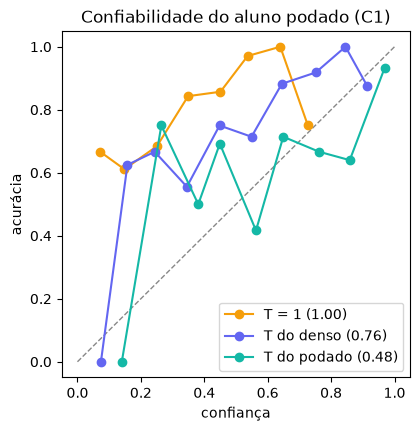

In [7]:
def confiabilidade(p, rot, bins=10):
    conf, acerto = p.max(1), p.argmax(1) == rot
    bordas = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(conf, bordas) - 1, 0, bins - 1)
    return [(conf[idx == b].mean(), acerto[idx == b].mean()) for b in range(bins) if (idx == b).any()]

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], "--", color="#888", lw=1)
for t, cor, nome in ((1.0, "#f59e0b", "T = 1"), (T_DENSO, "#6366f1", "T do denso"), (T, "#14b8a6", "T do podado")):
    c, a = zip(*confiabilidade(softmax(pl / t), rot))
    plt.plot(c, a, "o-", color=cor, label=f"{nome} ({t:.2f})")
plt.xlabel("confiança"); plt.ylabel("acurácia"); plt.title("Confiabilidade do aluno podado (C1)"); plt.legend(); plt.show()

**Leitura.** Podado e sem temperatura, o aluno é muito **subconfiante** (confiança bem abaixo da acurácia): zerar metade dos pesos encolhe os logits em cerca de 35%. O T do denso corrige só parte disso; o T ajustado no próprio modelo podado, menor, devolve a calibração. Nos 5 folds (capítulo, Seção 6.2): T = 0,48, ECE de 0,425 para 0,066 e NLL de 1,590 para 0,962; com o T = 0,76 do denso, o ECE ficaria em 0,234.

Em vez de dividir no app, **dobramos 1/T nos pesos e no bias da cabeça** (`scale_head`): a conta é exata e o Flutter recebe os logits já calibrados.

## 4. A decisão do app nas 61 classes

O app mostra a CM mais provável quando a probabilidade dela passa de um limiar e, abaixo dele, diz "em transição". Variar o limiar troca **cobertura** (em quantas pausas o app responde) por **acerto entre as respondidas**. Como CMs vizinhas dividem a probabilidade, o app também mostra as **três mais prováveis** (top-3).

Medimos nas 1.160 pausas fora do fold do aluno podado, com o T dos 5 folds (o do modelo do app). Os números são os do capítulo.

In [8]:
from research.optimization.calibration import decision_report

T_APP = fit_temperature(OOF_PODA, OOF_Y)
dec = decision_report(softmax(OOF_PODA / T_APP), OOF_Y)
print(f"T = {T_APP:.2f}, {dec['pausas']} pausas\n")
print(f"{'limiar':>7} {'cobertura':>10} {'acerto entre as respondidas':>28}")
for t, r in dec["limiares"].items():
    print(f"{t:>7} {r['cobertura']:10.1%} {r['acerto_entre_respondidas']:28.1%}")
print("\n" + " | ".join(f"{k}: {v:.1%}" for k, v in dec["top_k"].items()))
print("CMs com recall abaixo de 50%:", dec["recall_abaixo_de_50"])
print("pares mais trocados:", ", ".join(f"{p['cms'][0]}/{p['cms'][1]} ({p['pausas']})" for p in dec["pares_mais_trocados"][:5]))

T = 0.48, 1160 pausas

 limiar  cobertura  acerto entre as respondidas
   0.30      94.7%                        77.5%
   0.45      86.3%                        80.2%
   0.70      70.1%                        86.5%

top1: 75.2% | top2: 88.9% | top3: 92.4%
CMs com recall abaixo de 50%: [25, 27, 32, 38, 42, 47]
pares mais trocados: 46/47 (23), 42/43 (18), 15/38 (9), 44/45 (8), 27/28 (7)


**Leitura.** No limiar do app (0,45), ele responde em ~86% das pausas e acerta ~80% das respostas: uma em cada cinco ainda está errada. Por isso o card mostra o top-3: a CM certa está entre as três primeiras em ~92% das pausas. As CMs que mais erram são justamente as de pares vizinhos (46/47, 42/43, 15/38), que diferem pela posição de um dedo.

## 5. Quantização Int8 (PTQ) e o arquivo do app

Três passos, com as mesmas funções que geraram o modelo do app:

1. `export_float`: PyTorch → TFLite float32 com a assinatura do app (`rgb` NHWC e `landmarks`), com 1/T já dobrado na cabeça.
2. `quantize_int8`: pesos Int8 por canal e ativações Int8 calibradas por min/max nos frames de calibração (só atores de treino). Entrada, saída e o ramo dos pontos continuam float32 (`*_int8_lmfloat.tflite`).
3. Medir no TFLite: acurácia, calibração, tamanho e latência, comparando cada arquivo com a própria referência FP32.

Detalhes que só apareceram no celular (e que o código já resolve): o LiteRT 1.4 do `tflite_flutter` não tem `SQRT` em Int8, então o ramo dos pontos fica em float; ele também não lê pesos guardados fora do flatbuffer (`inline_buffers`); e o pooling adaptativo virava um `GATHER_ND` fora do XNNPACK (trocado por média).

In [9]:
import gzip, time
from research.optimization.quantizer import export_float, quantize_int8, scale_head
from research.optimization.eval_tflite import tflite_logits

calib = [{"rgb": dados["calib_rgb"][i:i+1].astype(np.float32) / 255,
          "landmarks": dados["calib_landmarks"][i:i+1]} for i in range(len(dados["calib_rgb"]))]

def exporta(m, nome, t):
    m = scale_head(copy.deepcopy(m), t)
    flt = export_float(m, SAIDA / f"{nome}_float.tflite", 224)
    return m, flt, quantize_int8(flt, calib, SAIDA / f"{nome}_int8_lmfloat.tflite", landmarks_float=True)

arquivos = {"denso": exporta(modelo, "denso", T_DENSO), "lamp50": exporta(PODADO, "lamp50", T)}

I0000 00:00:1792868130.429627 2091975 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


W1024 15:55:33.261000 2091975 .venv-tflite/lib/python3.12/site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


... (184 outputs left out)


Running Calibration::  99%|█████████▉| 13513/13600 [00:06<00:00, 2167.26it/s]


Applying Transformations to tensors::   0%|          | 0/198 [00:00<?, ?it/s]


Applying Transformations to tensors:: 100%|██████████| 198/198 [00:00<00:00, 104239.01it/s]

Model name: /home/alguem/Documentos/SignEdge/research/experiments/lab/lamp50_float.tflite
Original model size: 10.03 MiB
Quantized model size: 3.01 MiB
Quantization Ratio: 0.30 (3.3x smaller)
Total time: 59.84 ms


In [10]:
from ai_edge_litert.interpreter import Interpreter

VISTAS = list(lotes())

def latencia_ms(caminho, repeticoes=50):
    run = Interpreter(str(caminho), num_threads=1).get_signature_runner("serving_default")
    x = {"rgb": VISTAS[0][0][:1], "landmarks": VISTAS[0][1][:1]}
    for _ in range(5): run(**x)
    t = []
    for _ in range(repeticoes):
        s = time.perf_counter(); run(**x); t.append(time.perf_counter() - s)
    return 1000 * float(np.median(t))

print(f"{'arquivo':28} {'MiB':>6} {'gzip':>6} {'ms (1 thread)':>13}  pausa  | ECE   | top-1 = FP32")
for nome, (m_cal, *caminhos) in arquivos.items():
    referencia = logits_pytorch(m_cal)
    for caminho in caminhos:
        lg = tflite_logits(caminho, VISTAS)
        m = metricas(lg)
        mib = caminho.stat().st_size / 2**20
        gz = len(gzip.compress(caminho.read_bytes(), 9)) / 2**20
        igual = (lg.argmax(1) == referencia.argmax(1)).mean()
        print(f"{caminho.name:28} {mib:6.2f} {gz:6.2f} {latencia_ms(caminho):13.1f}  "
              f"{m['pausa_61']:6.1%} | {m['ece_pausa']:.3f} | {igual:.1%}")

arquivo                         MiB   gzip ms (1 thread)  pausa  | ECE   | top-1 = FP32


denso_float.tflite            10.03   9.22           4.0   81.0% | 0.085 | 100.0%


denso_int8_lmfloat.tflite      3.01   2.43           2.3   80.1% | 0.080 | 97.1%


lamp50_float.tflite           10.03   5.70           4.0   81.0% | 0.108 | 100.0%


lamp50_int8_lmfloat.tflite     3.01   1.73           2.3   79.6% | 0.084 | 98.0%


**Leitura.**

- **Int8**: ~3,3× menor que o float e mais rápido, com a acurácia praticamente igual à do FP32. Não chega a 4× porque os vieses ficam em int32, cada canal guarda escala e ponto zero, e o ramo dos pontos continua float32.
- **Poda e tamanho**: o `.tflite` podado tem **o mesmo número de bytes** e **a mesma latência** do denso. O TFLite guarda os zeros como pesos densos, e o XNNPACK Int8 não tem kernel esparso. O ganho aparece só no **comprimido** (gzip), ou seja, no download. Esparsidade não é velocidade: para isso, poda **estruturada** (canais inteiros).
- **Latência**: medida na CPU desta máquina. No Redmi Note 10S (Helio G95), o classificador Int8 leva ~8,6 ms isolado no XNNPACK, podado ou denso.

Resultado oficial do projeto (aluno treinado em C1–C5, podado, T = 0,48, Int8 com pontos em float32, medido **uma vez** no ator C6): **76,2%** por pausa nas 61 classes.

## 6. Implantação no Flutter

O app (`mobile/`) roda tudo no aparelho, sem rede: MediaPipe Hands (palma + 21 pontos, também em `.tflite`) → vista 224 → este modelo → decisão nas 61 CMs.

**Contrato do `model_int8.tflite`**

| tensor | forma | conteúdo |
|---|---|---|
| `rgb` | (1, 224, 224, 3) float32 | vista 224 em [0, 1], NHWC (a normalização do ImageNet está dentro do modelo) |
| `landmarks` | (1, 21, 2) float32 | os 21 pontos do MediaPipe em pixels da vista |
| saída | (1, 61) float32 | logits já calibrados (1/T na cabeça) |

**Passos**

1. Baixe o `lamp50_int8_lmfloat.tflite` (próxima célula) e copie para `mobile/assets/model_int8.tflite`.
2. `cd mobile && flutter pub get && flutter run --release` com o celular Android no USB (depuração USB ligada; em Xiaomi, também *Instalar via USB* e a tela desbloqueada na hora da instalação).
3. No app: telemetria (FPS, ms da mão e do SignEdge), a vista 224 desenhada sobre a mão e o card com a CM ativa, o top-3 e o catálogo das 61 CMs.

In [11]:
import shutil
modelo_app = arquivos["lamp50"][2]  # podado, 1/T na cabeça, Int8 com o ramo dos pontos em float32
destino = RAIZ / "mobile/assets/model_int8.tflite"
if EM_COLAB:
    from google.colab import files
    files.download(str(modelo_app))  # copie para mobile/assets/model_int8.tflite no seu repositório
else:
    print("Para trocar o modelo do app (o oficial continua em mobile/assets/):")
    print(f"  cp {modelo_app} {destino}")

Para trocar o modelo do app (o oficial continua em mobile/assets/):
  cp /home/alguem/Documentos/SignEdge/research/experiments/lab/lamp50_int8_lmfloat.tflite /home/alguem/Documentos/SignEdge/mobile/assets/model_int8.tflite


**Confira no celular.** A célula abaixo pega uma pausa do C1 e mostra o que o seu arquivo responde para ela. Faça a mesma configuração de mão diante da câmera e compare com o card do app: o top-3 deve trazer a mesma CM (o celular vê outra mão, outra luz e outro fundo, então as probabilidades mudam).

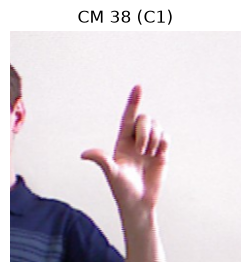

CM 38 (90%) · CM 35 (3%) · CM 15 (2%)


In [12]:
cm_teste = 38
i = int(np.flatnonzero(ROTULOS == cm_teste - 1)[0])
saida = tflite_logits(modelo_app, [(RGB[i:i+1].astype(np.float32) / 255, PONTOS[i:i+1])])[0]
p = softmax(saida[None])[0]
top = np.argsort(-p)[:3]
plt.figure(figsize=(3, 3)); plt.imshow(RGB[i]); plt.axis("off")
plt.title(f"CM {cm_teste} (C1)"); plt.show()
print(" · ".join(f"CM {c + 1} ({p[c]:.0%})" for c in top))